In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz

# ---------- Stage 1: Specification (fc, Q) ----------
f0 = 10200.0      # cutoff frequency (Hz)
fs = 48000.0      # sampling frequency (Hz)
Q  = 0.707        # Butterworth (maximally flat)

assert f0 < fs / 2, "f0 must be below Nyquist (fs/2)"

In [2]:
# ---------- Stage 2: Analog poles (s-domain) ----------
w0 = 2 * np.pi * f0
poles = np.roots([1, w0 / Q, w0**2])
print("Analog poles (rad/s):", poles)

zeta = 1 / (2 * Q)
print(f"Damping factor zeta = {zeta:.3f}")

Analog poles (rad/s): [-45324.25044783+45310.56045669j -45324.25044783-45310.56045669j]
Damping factor zeta = 0.707


In [3]:
# ---------- Stage 3: Digital coefficients (bilinear transform) ----------
w0d = 2 * np.pi * f0 / fs
alpha = np.sin(w0d) / (2 * Q)

a0 = 1 + alpha
a1 = -2 * np.cos(w0d) / a0
a2 = (1 - alpha) / a0

b0 = ((1 - np.cos(w0d)) / 2) / a0
b1 = 2 * b0
b2 = b0

K = 1.0   # set K = 3 - 1/Q to match an analog Sallen-Key circuit's gain
b0, b1, b2 = K * b0, K * b1, K * b2

print(f"b0={b0:.4f} b1={b1:.4f} b2={b2:.4f}  a1={a1:.4f} a2={a2:.4f}")

b_coeffs = [b0, b1, b2]
a_coeffs = [1, a1, a2]

b0=0.2271 b1=0.4542 b2=0.2271  a1=-0.2766 a2=0.1851


In [4]:
# ---------- Stage 4: Code — filter a multi-tone sine input ----------
duration = 0.02
t = np.arange(0, duration, 1/fs)

f_test = [2000, 8000, 10200, 15000, 20000]  # below / near / at / above fc
x = np.zeros_like(t)
for f in f_test:
    x += np.sin(2 * np.pi * f * t)
x /= len(f_test)

y = lfilter(b_coeffs, a_coeffs, x)  # y[n] = b0 x[n] + b1 x[n-1] + b2 x[n-2] - a1 y[n-1] - a2 y[n-2]

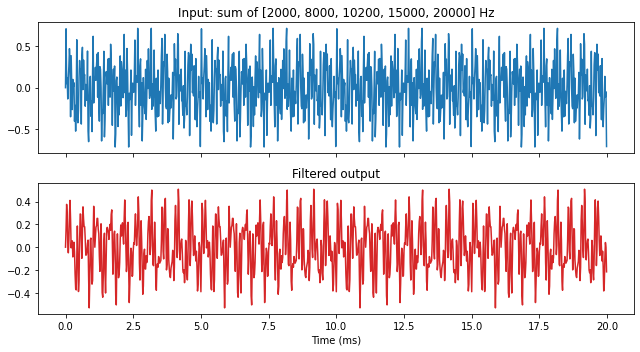

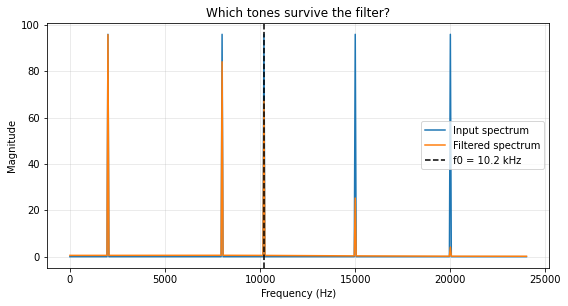

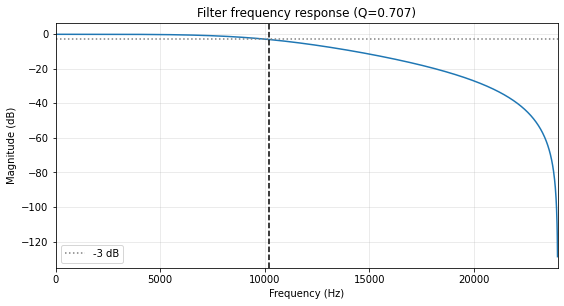

In [5]:
# ---------- Plots ----------
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(t * 1000, x); axes[0].set_title(f'Input: sum of {f_test} Hz')
axes[1].plot(t * 1000, y, color='tab:red'); axes[1].set_title('Filtered output')
axes[1].set_xlabel('Time (ms)')
plt.tight_layout(); plt.show()

N = len(x)
f_axis = np.fft.rfftfreq(N, d=1/fs)
X, Y = np.abs(np.fft.rfft(x)), np.abs(np.fft.rfft(y))

plt.figure(figsize=(9, 4.5))
plt.plot(f_axis, X, label='Input spectrum')
plt.plot(f_axis, Y, label='Filtered spectrum')
plt.axvline(f0, color='k', linestyle='--', label=f'f0 = {f0/1000:.1f} kHz')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Magnitude'); plt.legend(); plt.grid(alpha=0.3)
plt.title('Which tones survive the filter?')
plt.show()

w, h = freqz(b_coeffs, a_coeffs, worN=2048, fs=fs)
plt.figure(figsize=(9, 4.5))
plt.plot(w, 20 * np.log10(np.abs(h) + 1e-12))
plt.axvline(f0, color='k', linestyle='--')
plt.axhline(-3, color='gray', linestyle=':', label='-3 dB')
plt.xlim(0, fs/2)
plt.xlabel('Frequency (Hz)'); plt.ylabel('Magnitude (dB)')
plt.title(f'Filter frequency response (Q={Q})'); plt.legend(); plt.grid(alpha=0.3)
plt.show()